# 4 · Can machine learning time the factors? Linear models, ridge, neural nets and volatility management
"Smart beta" products hold the market and the classic long-short factors (size, value, profitability, investment, momentum). A natural next step is to **time** them: hold more when the expected return is high. This notebook asks whether that can be done out of sample with linear regression, ridge regression and a small neural network, compared with the simplest alternative, **volatility management**: hold less when recent volatility is high (Moreira & Muir, 2017).

**Data:** monthly Fama-French five factors plus momentum (Ken French data library, July 1963 to September 2026), monthly realised variance from daily factor returns, and the term and default spreads from FRED.

**Protocol:** every forecast uses only information available at the end of the previous month. Models are refit each January on an expanding window, forecasts start in January 1990, and accuracy is measured by the Campbell-Thompson out-of-sample R² against the expanding historical mean.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.neural_network import MLPRegressor
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); DATA = pathlib.Path("../data")
from finml import timing
ff = pd.read_csv(DATA / "ff_factors_monthly.csv", index_col=0, parse_dates=True)
F = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]
print(f"{len(ff)} months, {ff.index[0]:%b %Y} to {ff.index[-1]:%b %Y}")
desc = pd.DataFrame({"mean % / month": 100 * ff[F].mean(), "s.d. % / month": 100 * ff[F].std(),
                     "Sharpe (annual)": ff[F].mean() / ff[F].std() * np.sqrt(12), "first-order autocorrelation": ff[F].apply(lambda s: s.autocorr())})
desc.round(3)

759 months, Jul 1963 to Sep 2026


,mean % / month,s.d. % / month,Sharpe (annual),first-order autocorrelation
Mkt-RF,0.600,4.455,0.466,0.040
SMB,0.180,3.023,0.206,0.049
HML,0.292,2.969,0.340,0.158
RMW,0.247,2.289,0.374,0.139
CMA,0.245,2.072,0.409,0.131
Mom,0.604,4.209,0.497,0.034


## Predictors
For every factor: last month's return, the trailing 12-month return and the log of last month's realised variance; plus the term spread (10-year minus 3-month Treasury) and the default spread (BAA minus AAA). That is 20 predictors, all lagged one month.

In [2]:
X = pd.DataFrame(index=ff.index)
for f in F:
    X[f"{f} 1m"] = ff[f]; X[f"{f} 12m"] = ff[f].rolling(12).sum(); X[f"{f} log var"] = np.log(ff[f"rv_{f}"])
X["term spread"] = ff["term_spread"]; X["default spread"] = ff["default_spread"]
X = X.shift(1).dropna()
Y = ff.loc[X.index, F]
start = int(np.searchsorted(X.index, pd.Timestamp("1990-01-31")))
print(f"{X.shape[1]} predictors; estimation sample from {X.index[0]:%b %Y}; {len(X) - start} out-of-sample months from {X.index[start]:%b %Y}")
models = {
    "OLS (20 predictors)": lambda: make_pipeline(StandardScaler(), LinearRegression()),
    "ridge (penalty chosen by CV)": lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 30))),
    "neural net (16-8, early stopping, 5-seed average)": None,
}
class MLPEnsemble:
    def __init__(self, seeds=5): self.seeds = seeds
    def fit(self, X, y):
        # the target is standardised too: monthly returns are ~0.04 in size, far from the network's natural output scale
        self.mu, self.sd = y.mean(), y.std()
        self.m = [make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(16, 8), alpha=1e-2, early_stopping=True, validation_fraction=0.2, max_iter=500, random_state=s)).fit(X, (y - self.mu) / self.sd) for s in range(self.seeds)]
        return self
    def predict(self, X): return self.mu + self.sd * np.mean([m.predict(X) for m in self.m], axis=0)
models["neural net (16-8, early stopping, 5-seed average)"] = MLPEnsemble
fc = {}; hm = {}
for f in F:
    y = Y[f]; hm[f] = timing.historical_mean_forecast(y, start)
    for name, mk in models.items():
        fc[(f, name)] = timing.expanding_forecast(X, y, mk, start, refit=12)
r2 = pd.DataFrame({name: {f: 100 * timing.oos_r2(Y[f], fc[(f, name)], hm[f]) for f in F} for name in models})
r2.round(2).rename_axis("out-of-sample R², %")

20 predictors; estimation sample from Jul 1964; 441 out-of-sample months from Jan 1990


,OLS (20 predictors),ridge (penalty chosen by CV),"neural net (16-8, early stopping, 5-seed average)"
"out-of-sample R², %",,,
Mkt-RF,-5.38,-0.03,-9.99
SMB,-7.58,-0.19,-4.44
HML,-7.23,-0.53,-4.31
RMW,-4.58,-1.00,0.43
CMA,-7.56,-0.14,-7.09
Mom,-8.19,0.19,-6.28


## Does it pay? Timing strategies
Each month the exposure to a factor is w = forecast / (3 × variance forecast), capped between 0 and 2, where the variance forecast is last month's realised variance. Strategies are compared on Sharpe ratio with **holding the factor** (w = 1) and with the **volatility-managed** version (exposure ∝ 1 / last month's variance, scaled to the same volatility as the factor; Moreira & Muir, 2017). For a fair comparison, the historical-mean forecast is also turned into a timing rule.

In [3]:
def sharpe(r): r = r.dropna(); return r.mean() / r.std() * np.sqrt(12)
oos = Y.index[start:]
rows = {}
for f in F:
    y = Y[f].loc[oos]; var = ff[f"rv_{f}"].shift(1).loc[oos]
    row = {"hold factor": sharpe(y)}
    row["timing: historical mean"] = sharpe(timing.timing_weights(hm[f].loc[oos], var) * y)
    for name in models: row[f"timing: {name.split(' (')[0]}"] = sharpe(timing.timing_weights(fc[(f, name)].loc[oos], var) * y)
    row["volatility-managed"] = sharpe(timing.vol_managed(ff[f], ff[f"rv_{f}"]).loc[oos])
    rows[f] = row
sh = pd.DataFrame(rows).T
sh.round(2)

,hold factor,timing: historical mean,timing: OLS,timing: ridge,timing: neural net,volatility-managed
Mkt-RF,0.59,0.66,0.43,0.63,0.52,0.63
SMB,0.08,0.00,0.30,0.27,0.36,-0.02
HML,0.17,0.11,0.37,0.13,0.24,0.09
RMW,0.39,0.39,0.47,0.50,0.67,0.55
CMA,0.27,0.15,0.21,0.18,0.19,0.12
Mom,0.34,0.66,0.53,0.67,0.51,0.87


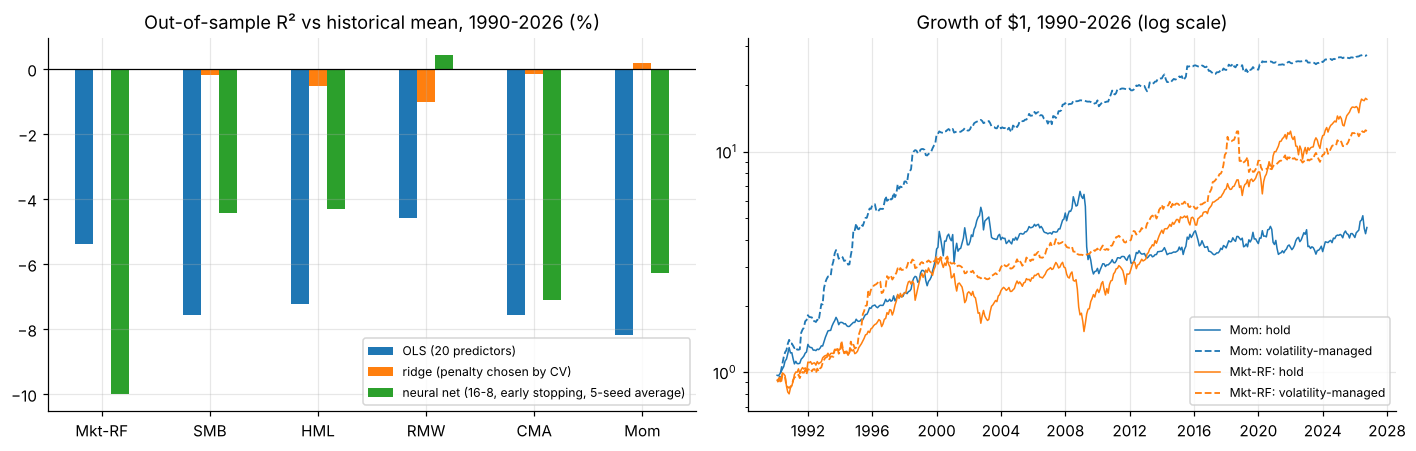

Momentum worst month, held: -34.4% (Apr 2009); volatility-managed: -7.9% (Jan 1990)
Momentum max drawdown, held: -58%; volatility-managed: -14%


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
r2.plot.bar(ax=ax[0], rot=0); ax[0].axhline(0, color="k", lw=0.8); ax[0].set_title("Out-of-sample R² vs historical mean, 1990-2026 (%)"); ax[0].legend(fontsize=8)
for f, c in [("Mom", "C0"), ("Mkt-RF", "C1")]:
    ax[1].plot((1 + Y[f].loc[oos]).cumprod(), color=c, lw=1, label=f"{f}: hold")
    ax[1].plot((1 + timing.vol_managed(ff[f], ff[f"rv_{f}"]).loc[oos]).cumprod(), color=c, ls="--", lw=1.2, label=f"{f}: volatility-managed")
ax[1].set_yscale("log"); ax[1].set_title("Growth of \\$1, 1990-2026 (log scale)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "factor_timing.png", bbox_inches="tight"); plt.show()
mom = Y["Mom"].loc[oos]; vm = timing.vol_managed(ff["Mom"], ff["rv_Mom"]).loc[oos]
print(f"Momentum worst month, held: {100 * mom.min():.1f}% ({mom.idxmin():%b %Y}); volatility-managed: {100 * vm.min():.1f}% ({vm.idxmin():%b %Y})")
print(f"Momentum max drawdown, held: {100 * ((1 + mom).cumprod() / (1 + mom).cumprod().cummax() - 1).min():.0f}%; volatility-managed: {100 * ((1 + vm).cumprod() / (1 + vm).cumprod().cummax() - 1).min():.0f}%")

### Is the volatility-managed improvement statistically meaningful?
A block bootstrap of 36-month blocks gives a 90% interval for the Sharpe-ratio difference (managed minus held) for each factor.

In [5]:
rng = np.random.default_rng(0); B = 2000; blk = 36
def boot_diff(a, b):
    n = len(a); out = []
    A, Bv = a.to_numpy(), b.to_numpy()
    for _ in range(B):
        idx = np.concatenate([np.arange(s, s + blk) % n for s in rng.integers(0, n, n // blk + 1)])[:n]
        out.append(A[idx].mean() / A[idx].std() * np.sqrt(12) - Bv[idx].mean() / Bv[idx].std() * np.sqrt(12))
    return np.percentile(out, [5, 50, 95])
bt = pd.DataFrame({f: boot_diff(timing.vol_managed(ff[f], ff[f"rv_{f}"]).loc[oos], Y[f].loc[oos]) for f in F}, index=["5%", "median", "95%"]).T
bt.round(2).rename_axis("Sharpe gain, managed − held")

,5%,median,95%
"Sharpe gain, managed − held",,,
Mkt-RF,-0.23,0.03,0.29
SMB,-0.27,-0.10,0.06
HML,-0.32,-0.07,0.18
RMW,-0.15,0.16,0.42
CMA,-0.35,-0.13,0.09
Mom,0.30,0.51,0.74


## Findings
* **No model forecasts factor returns better than their historical average.** Out of sample (1990-2026, 441 months), OLS on 20 predictors has an R² of -5% to -8% for every factor. The neural network does no better (-10% to +0.4%; only profitability, RMW, is marginally positive). Ridge regression shrinks almost everything to the mean and lands near zero (-1.0% to +0.2%). With monthly factor returns, extra flexibility adds estimation noise faster than it finds signal.
* **The timing gains that do appear come from risk, not from return forecasts.** Every timing rule divides by last month's variance. That is why even the historical-mean rule, which has no return signal at all, lifts momentum's Sharpe ratio from 0.34 to 0.66. The neural net's apparent gains for SMB, HML and RMW (Sharpe 0.24-0.67 vs 0.08-0.39 held) come with negative R², so they should be treated as unproven.
* **Volatility management works for momentum and is statistically clear.** Scaling momentum by the inverse of last month's realised variance raises its Sharpe ratio from 0.34 to 0.87. The 90% block-bootstrap interval for the gain is +0.30 to +0.74. It also avoids momentum's crashes: the worst month falls from -34% (April 2009) to -8%, and the maximum drawdown from -58% to -14%.
* **For the other factors the evidence is weak.** The market (0.59 → 0.63) and profitability (0.39 → 0.55) improve a little, and size, value and investment get slightly worse. All their bootstrap intervals include zero. This matches later critiques of Moreira-Muir (e.g. Cederburg et al., 2020): the robust case is momentum, whose crashes follow high-volatility periods.
* **Caveats:** the volatility-managed series is scaled to the factor's full-sample volatility, which does not change the Sharpe ratio but does affect the drawdown figures. Leverage of up to several times in calm months and trading costs are ignored. Factor returns are paper long-short portfolios, before fees.